# HAM10000 Dataset - Exploratory Data Analysis (EDA)
We will explore the metadata of the HAM10000 dataset ("Human Against Machine"), which is a large collection of multi-source dermatoscopic images of common pigmented skin lesions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata
df = pd.read_csv('/content/HAM10000_metadata.csv')

# Display basic information
print("Dataset Shape:", df.shape)
display(df.info())
display(df.head())

Dataset Shape: (10015, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB


None

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


### Check for Missing Values

In [2]:
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

Missing values per column:
age    57
dtype: int64


### Visualizing the Distributions of Categorical Variables

/tmp/ipykernel_4035/2955987100.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dx', order=df['dx'].value_counts().index, ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_4035/2955987100.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=45)
/tmp/ipykernel_4035/2955987100.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sex', order=df['sex'].value_counts().index, ax=axes[0, 1], palette='pastel')
/tmp/ipykernel_4035/2955987100.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of tic

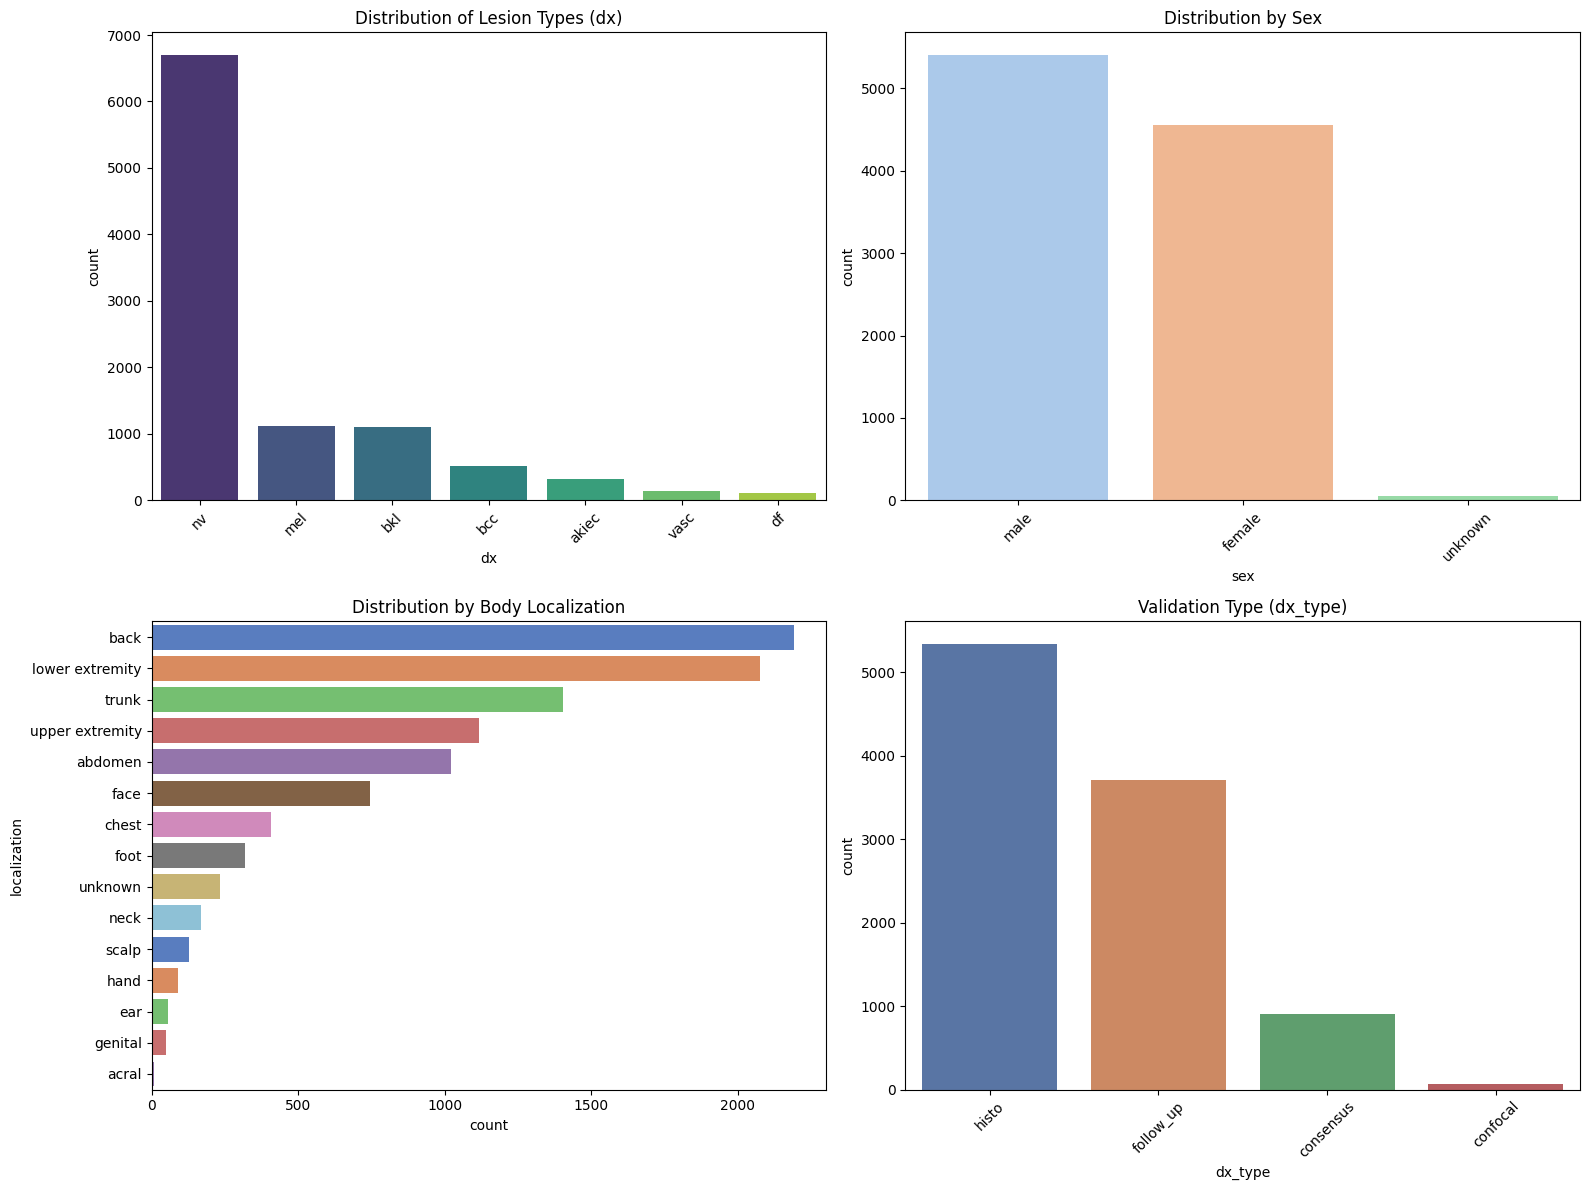

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Class distribution (dx)
sns.countplot(data=df, x='dx', order=df['dx'].value_counts().index, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Distribution of Lesion Types (dx)')
axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=45)

# Sex distribution
sns.countplot(data=df, x='sex', order=df['sex'].value_counts().index, ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Distribution by Sex')
axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=45)

# Localization distribution
sns.countplot(data=df, y='localization', order=df['localization'].value_counts().index, ax=axes[1, 0], palette='muted')
axes[1, 0].set_title('Distribution by Body Localization')

# Type of Ground Truth (dx_type)
sns.countplot(data=df, x='dx_type', order=df['dx_type'].value_counts().index, ax=axes[1, 1], palette='deep')
axes[1, 1].set_title('Validation Type (dx_type)')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

### Age Distribution of Patients

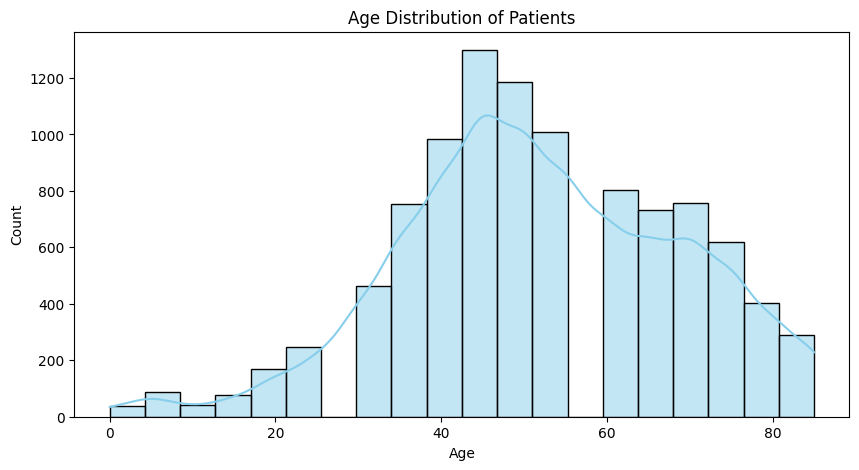

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(df['age'].dropna(), bins=20, kde=True, color='skyblue')
plt.title('Age Distribution of Patients')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

## Data Preprocessing, Splitting (80/20), and Decision Tree Classification

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Handle missing values in 'age'
df_clean = df.copy()
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())

# Encode categorical metadata columns for the model
le_sex = LabelEncoder()
le_loc = LabelEncoder()
le_dx_type = LabelEncoder()

df_clean['sex_encoded'] = le_sex.fit_transform(df_clean['sex'])
df_clean['localization_encoded'] = le_loc.fit_transform(df_clean['localization'])
df_clean['dx_type_encoded'] = le_dx_type.fit_transform(df_clean['dx_type'])

# Define Features (X) and Target (y)
features = ['age', 'sex_encoded', 'localization_encoded', 'dx_type_encoded']
X = df_clean[features]
y = df_clean['dx']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8012, 4)
Testing set shape: (2003, 4)


In [6]:
# Train Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42, max_depth=6)
clf.fit(X_train, y_train)

# Predictions
y_pred = clf.predict(X_test)

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.7059

Classification Report:
              precision    recall  f1-score   support

       akiec       0.00      0.00      0.00        65
         bcc       0.00      0.00      0.00       103
         bkl       0.44      0.46      0.45       220
          df       0.00      0.00      0.00        23
         mel       0.27      0.36      0.31       223
          nv       0.83      0.92      0.87      1341
        vasc       0.00      0.00      0.00        28

    accuracy                           0.71      2003
   macro avg       0.22      0.25      0.23      2003
weighted avg       0.64      0.71      0.67      2003



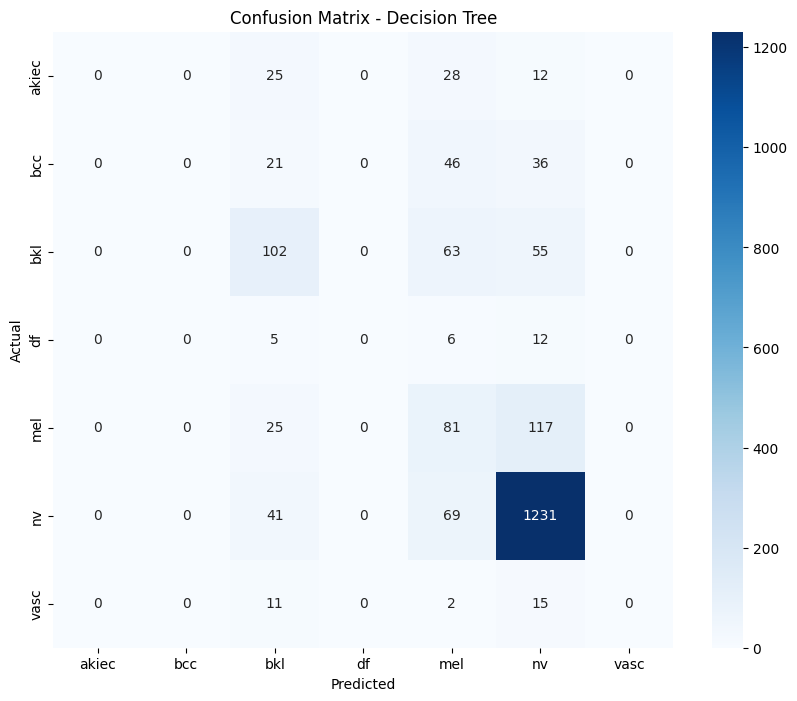

In [7]:
# Visualize Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

## Advanced AI Modeling: Random Forest Classifier
To improve performance and handle class imbalance better, we will train a Random Forest ensemble classifier.

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest Classifier with class weighting to handle imbalance
rf_clf = RandomForestClassifier(random_state=42, n_estimators=100, max_depth=10, class_weight='balanced')
rf_clf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf_clf.predict(X_test)

# Evaluation Metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {rf_accuracy:.4f}\n")
print("Classification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Accuracy: 0.6281

Classification Report (Random Forest):
              precision    recall  f1-score   support

       akiec       0.22      0.65      0.33        65
         bcc       0.20      0.49      0.29       103
         bkl       0.54      0.35      0.42       220
          df       0.18      0.57      0.27        23
         mel       0.31      0.37      0.34       223
          nv       0.97      0.73      0.84      1341
        vasc       0.14      0.39      0.21        28

    accuracy                           0.63      2003
   macro avg       0.37      0.51      0.38      2003
weighted avg       0.77      0.63      0.68      2003



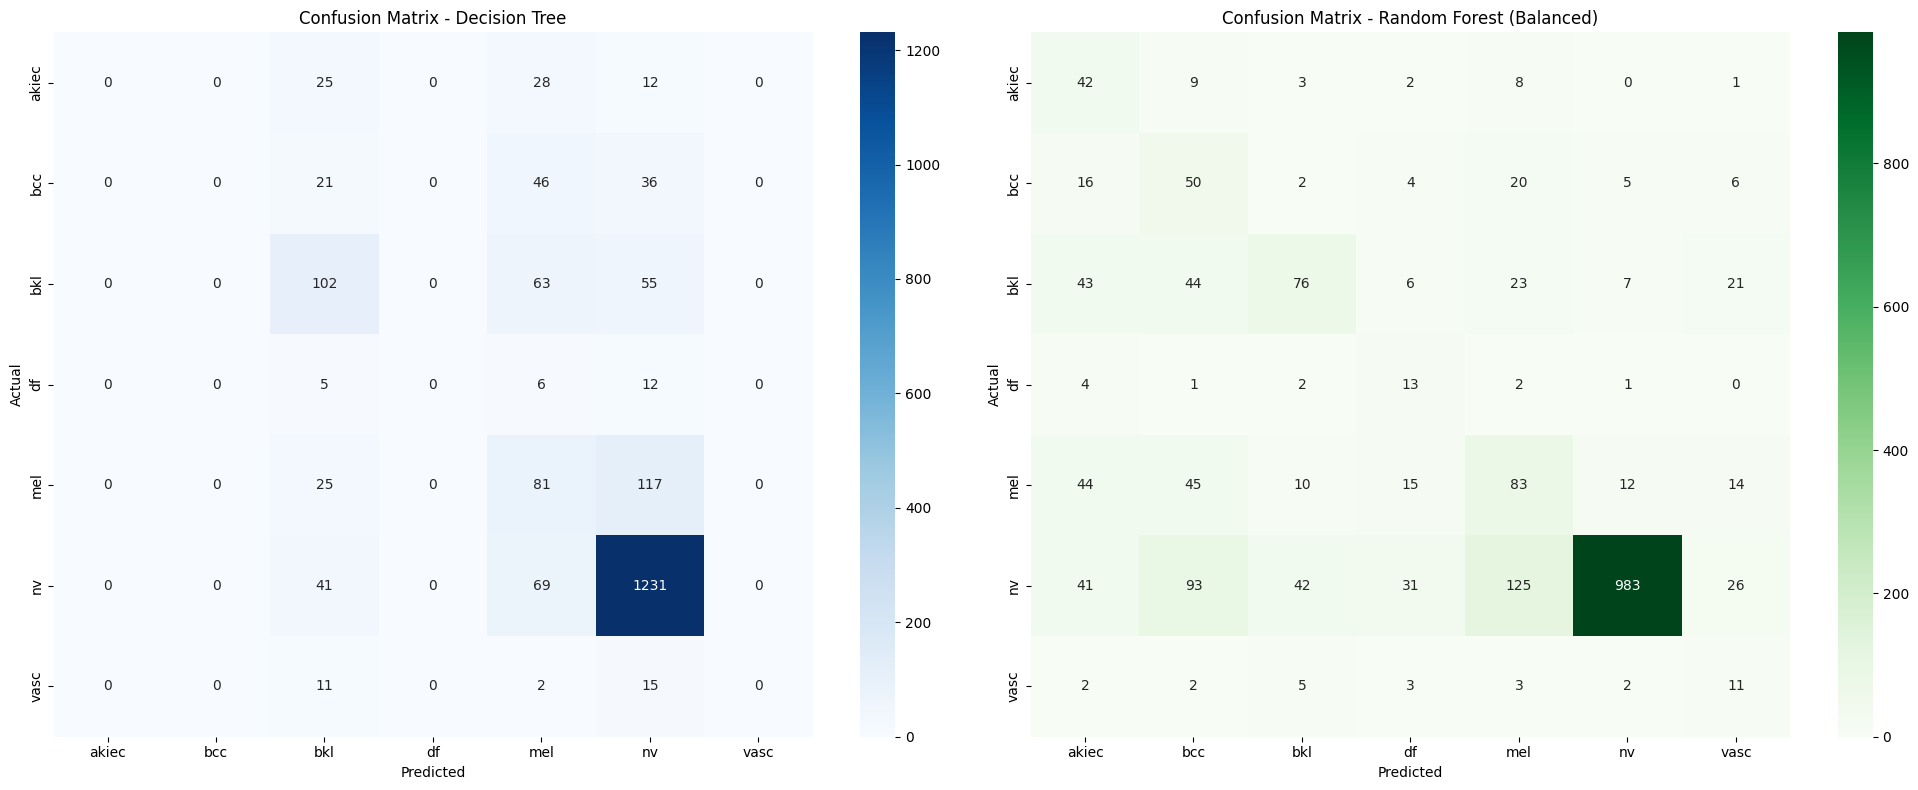

In [9]:
# Compare Decision Tree vs Random Forest Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Decision Tree Heatmap
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix - Decision Tree')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Random Forest Heatmap
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', xticklabels=rf_clf.classes_, yticklabels=rf_clf.classes_, cmap='Greens', ax=axes[1])
axes[1].set_title('Confusion Matrix - Random Forest (Balanced)')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

### Prediction Samples: Actual vs. Predicted Labels
We will select 10 random samples from our testing dataset and compare their actual ground-truth diagnoses with the predictions made by both the baseline Decision Tree and our balanced Random Forest model.

In [10]:
# Select 10 random samples from the testing set
sample_indices = X_test.sample(n=10, random_state=42).index

# Get features and actual values
sample_features = X_test.loc[sample_indices]
sample_actuals = y_test.loc[sample_indices]

# Generate predictions
sample_preds_dt = clf.predict(sample_features)
sample_preds_rf = rf_clf.predict(sample_features)

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Index': sample_indices,
    'Age': sample_features['age'],
    'Actual Label': sample_actuals,
    'Predicted (Decision Tree)': sample_preds_dt,
    'Predicted (Random Forest)': sample_preds_rf
})

display(comparison_df.reset_index(drop=True))

,Index,Age,Actual Label,Predicted (Decision Tree),Predicted (Random Forest)
0,2147,65.0,mel,nv,mel
1,2335,5.0,vasc,nv,vasc
2,2428,80.0,vasc,bkl,bkl
3,6952,65.0,nv,mel,df
4,5304,40.0,nv,nv,nv
5,2585,75.0,bcc,mel,bcc
6,1362,45.0,mel,nv,mel
7,4935,50.0,nv,nv,nv
8,8116,30.0,nv,nv,nv
9,5499,35.0,nv,nv,nv


### Visualizing Actual vs. Predicted Labels for the 10 Samples
Let's plot the comparison using a grouped categorical plot to visually see which model matches the actual diagnosis for each sample.

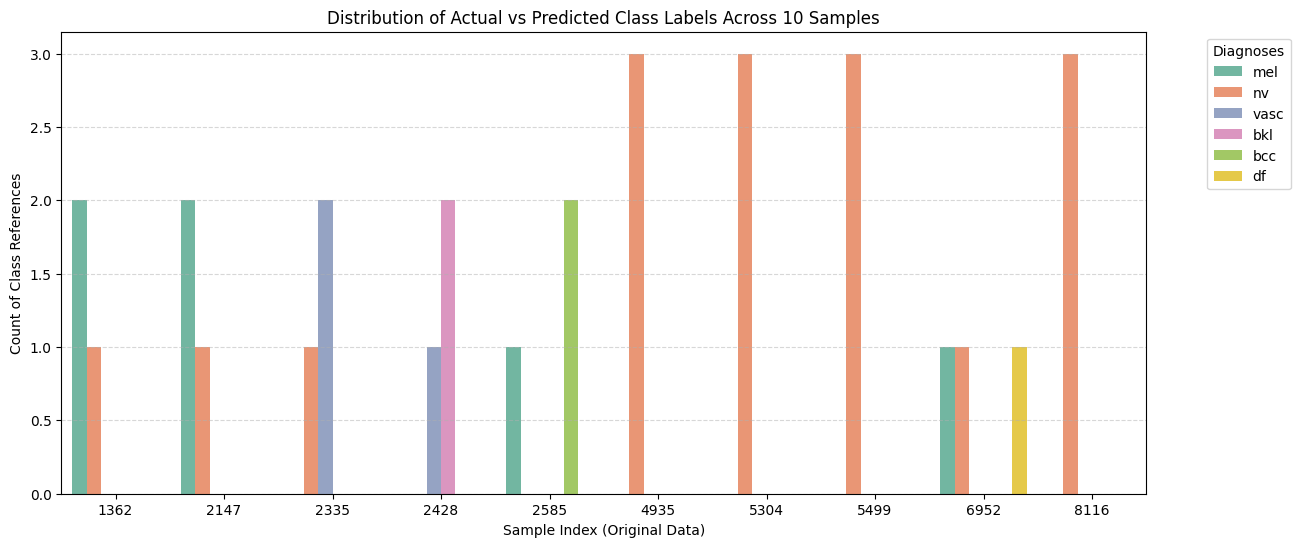

In [11]:
# Reshape comparison data for visualization
comparison_melted = pd.melt(
    comparison_df.reset_index(),
    id_vars=['index', 'Age'],
    value_vars=['Actual Label', 'Predicted (Decision Tree)', 'Predicted (Random Forest)'],
    var_name='Model/Type',
    value_name='Diagnosis'
)

plt.figure(figsize=(14, 6))
sns.countplot(data=comparison_melted, x='index', hue='Diagnosis', palette='Set2')
plt.title('Distribution of Actual vs Predicted Class Labels Across 10 Samples')
plt.xlabel('Sample Index (Original Data)')
plt.ylabel('Count of Class References')
plt.legend(title='Diagnoses', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

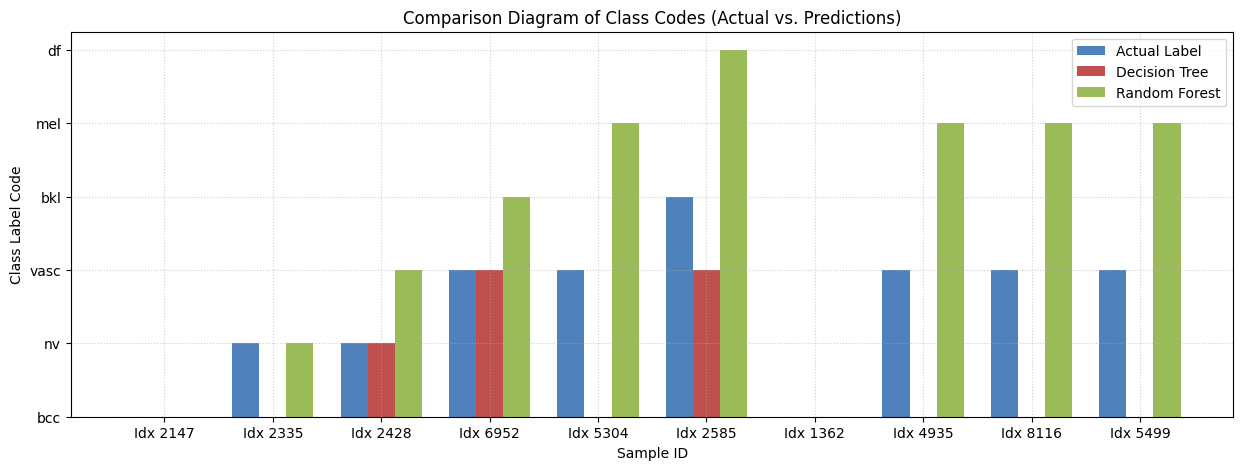

In [12]:
# Direct side-by-side comparative timeline
plt.figure(figsize=(15, 5))
x = np.arange(len(comparison_df))
width = 0.25

plt.bar(x - width, comparison_df['Actual Label'].factorize()[0], width, label='Actual Label', color='#4F81BD')
plt.bar(x, comparison_df['Predicted (Decision Tree)'].factorize()[0], width, label='Decision Tree', color='#C0504D')
plt.bar(x + width, comparison_df['Predicted (Random Forest)'].factorize()[0], width, label='Random Forest', color='#9BBB59')

# Customize mapping labels for comparison
all_unique_labels = list(set(comparison_df['Actual Label']).union(set(comparison_df['Predicted (Decision Tree)'])).union(set(comparison_df['Predicted (Random Forest)'])))
plt.yticks(ticks=np.arange(len(all_unique_labels)), labels=all_unique_labels)
plt.xticks(ticks=x, labels=[f"Idx {i}" for i in comparison_df['Index']])

plt.title('Comparison Diagram of Class Codes (Actual vs. Predictions)')
plt.xlabel('Sample ID')
plt.ylabel('Class Label Code')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Saving Models and Verifying File Size (< 25 MB)
We will use `joblib` with compression to save both models to disk and verify that their sizes remain well below the 25 MB threshold.

In [13]:
import joblib
import os

# Save the Decision Tree model
dt_model_path = 'decision_tree_model.joblib'
joblib.dump(clf, dt_model_path, compress=3)

# Save the Random Forest model
rf_model_path = 'random_forest_model.joblib'
joblib.dump(rf_clf, rf_model_path, compress=3)

# Calculate and display file sizes
for path in [dt_model_path, rf_model_path]:
    size_bytes = os.path.getsize(path)
    size_mb = size_bytes / (1024 * 1024)
    print(f"{path}: {size_mb:.4f} MB ({(size_bytes/1024):.2f} KB)")

decision_tree_model.joblib: 0.0052 MB (5.32 KB)
random_forest_model.joblib: 2.4863 MB (2546.00 KB)


In [14]:
from google.colab import files

# Download the models to your local machine
files.download('decision_tree_model.joblib')
files.download('random_forest_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>